# Part 1: Probability Distributions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### loading data and getting main structure

In [2]:
df = pd.read_csv('GaltonFamilies.csv')
print(df.head())
print(df.columns.tolist())
print(df.shape)
# checking data types
print(df.info())
# checking missing values
print(df.isnull().sum())

   rownames family  father  mother  midparentHeight  children  childNum  \
0         1    001    78.5    67.0            75.43         4         1   
1         2    001    78.5    67.0            75.43         4         2   
2         3    001    78.5    67.0            75.43         4         3   
3         4    001    78.5    67.0            75.43         4         4   
4         5    002    75.5    66.5            73.66         4         1   

   gender  childHeight  
0    male         73.2  
1  female         69.2  
2  female         69.0  
3  female         69.0  
4    male         73.5  
['rownames', 'family', 'father', 'mother', 'midparentHeight', 'children', 'childNum', 'gender', 'childHeight']
(934, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 934 entries, 0 to 933
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rownames         934 non-null    int64  
 1   family           934 non-null   

### extracting the heights

In [3]:
#  Keep one mother-height observation per family
mothers = (df[['family', 'father']]
           .dropna(subset=['family', 'father'])
           .drop_duplicates(['family', 'father']))
mother_heights = mothers['father'].to_numpy(dtype=float)
child_heights = (df["childHeight"]
    .dropna()
    .to_numpy(dtype=float))
# Putting both populations into one unlabeled dataset
heights = np.concatenate([mother_heights,child_heights])
# verifying data
print("Number of mothers:", len(mother_heights))
print("Number of children:", len(child_heights))
print("Total observations:", len(heights))
print("First 10 pooled heights:", heights[:10])

Number of mothers: 205
Number of children: 934
Total observations: 1139
First 10 pooled heights: [78.5 75.5 75.  75.  75.  74.  74.  74.  74.5 74. ]


### exploring/ understanding data (calculating basic statistics and plot distibution to visualize whether two groups might be mixed together)

Overall mean: 67.20851624231783
Overall variance: 12.724062679938118
Overall standard deviation: 3.567080413999398
Minimum height: 56.0
Maximum height: 79.0


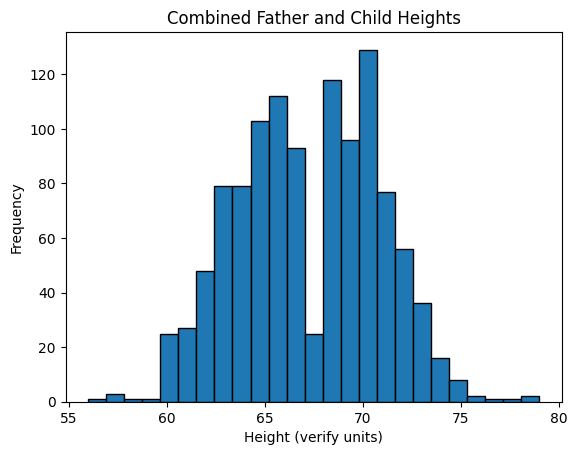

In [4]:
print("Overall mean:", np.mean(heights))
print("Overall variance:", np.var(heights))
print("Overall standard deviation:", np.std(heights))
print("Minimum height:", np.min(heights))
print("Maximum height:", np.max(heights))

plt.hist(heights, bins=25, edgecolor="black")
plt.xlabel("Height (verify units)")
plt.ylabel("Frequency")
plt.title("Combined Father and Child Heights")
plt.show()

#### Looking at the above graph it shows that there are two peaks(one at around 66 and other around 70) which means there are two distinct subgroups. The graph also shows the valley around 68 which indicates that the groups overlaps

## Question: "Should you or should you not simply draw a line at the dataset's global mean to split the data into two piles, and then calculate the mean of each pile?

#### Answer:  No, because the two populations are mixed together in a continuous space, their bell curves overlap significantly, which means shorter parents and taller children fall into the same height range. Drawing a hard line at the global mean creates a hard threshold that forces a data point entirely into one group or another. Instead we will use EM algorithm which calculates the posterior probability of each observation and preserve uncertainty when the distributions overlap.

### Probability density function to determine relative fit or density of each heights (which helps in determining probability of belonging to each component)

In [5]:
def gaussian_pdf(x, mean, variance):
    """
    Calculate the Gaussian probability density
    for each observation in x.
    """
    coefficient = 1 / np.sqrt(2 * np.pi * variance)

    exponent = -((x - mean) ** 2) / (2 * variance)

    return coefficient * np.exp(exponent)

### starting EM algorithm

#### Expectation stage (calculating the probability of belonging to each group for every single piece of data in dataset)

In [6]:
def expectation_step(x, means, variances, mixing):
    """
    Calculate the responsibility of each
    Gaussian component for each observation.
    """
    weighted_densities = np.column_stack([
        mixing[k] * gaussian_pdf(
            x, means[k], variances[k]
        )
        for k in range(2)
    ])

    totals = weighted_densities.sum(axis=1, keepdims=True)

    responsibilities = weighted_densities / totals

    return responsibilities

### Maximisation stage (to update models parameters)



In [7]:
def maximization_step(x, responsibilities):
    """
    Update means, variances and mixing proportions
    using the responsibilities from the E-step.
    """
    n = len(x)

    effective_counts = responsibilities.sum(axis=0)

    means = (
        (responsibilities * x[:, None]).sum(axis=0)
        / effective_counts
    )

    variances = (
        responsibilities * (x[:, None] - means) ** 2
    ).sum(axis=0) / effective_counts

    # Protect against zero or near-zero variance.
    variances = np.maximum(variances, 1e-6)

    mixing = effective_counts / n

    return means, variances, mixing

### calculating log-likelihood (to prove whether the EM algorithm is actually learning)

In [8]:
def calculate_log_likelihood(x, means, variances, mixing):
    """
    Measure how well the model explains
    the observed heights.
    """
    weighted_densities = np.column_stack([
        mixing[k] * gaussian_pdf(
            x, means[k], variances[k]
        )
        for k in range(2)
    ])

    total_density = weighted_densities.sum(axis=1)

    return np.sum(np.log(np.maximum(total_density, 1e-300)))

### all steps together, plus initialisation of guessing

In [9]:
def fit_em(x, max_iterations=500, tolerance=1e-6):
    """
    Fit a two-component Gaussian mixture using
    our own Expectation-Maximization implementation.
    """

    # Initial parameter estimates
    means = np.quantile(x, [0.25, 0.75])

    overall_variance = np.var(x)

    variances = np.array([
        overall_variance,
        overall_variance
    ], dtype=float)

    mixing = np.array([0.5, 0.5])

    history = []

    # Record iteration 0: initialization
    history.append({
        "iteration": 0,
        "means": means.copy(),
        "variances": variances.copy(),
        "mixing": mixing.copy(),
        "log_likelihood": calculate_log_likelihood(
            x, means, variances, mixing
        )
    })

    previous_ll = history[-1]["log_likelihood"]

    for iteration in range(1, max_iterations + 1):

        # E-step: estimate memberships
        responsibilities = expectation_step(
            x, means, variances, mixing
        )

        # M-step: update parameters
        means, variances, mixing = maximization_step(
            x, responsibilities
        )

        # Keep component 1 as the lower-mean component.
        order = np.argsort(means)
        means = means[order]
        variances = variances[order]
        mixing = mixing[order]

        # Measure the updated model
        current_ll = calculate_log_likelihood(
            x, means, variances, mixing
        )

        history.append({
            "iteration": iteration,
            "means": means.copy(),
            "variances": variances.copy(),
            "mixing": mixing.copy(),
            "log_likelihood": current_ll
        })

        # Stop if the log-likelihood barely changes
        if abs(current_ll - previous_ll) < tolerance:
            break

        previous_ll = current_ll

    return means, variances, mixing, history

In [10]:
# Run the EM algorithm
means, variances, mixing, history = fit_em(heights)

# Print the required tracking table
print(
    f"{'Iteration':<12}"
    f"{'μ1 ​(Children)':>12}"
    f"{'μ2​ (Pros)':>12}"
    f"{'σ1²':>12}"
    f"{'σ2²':>12}"
    f"{'π1':>10}"
    f"{'π2':>10}"
    f"{'Log-Likelihood':>20}"
)

for row in history[:3]:
    print(
        f"{row['iteration']:<12}"
        f"{row['means'][0]:>12.4f}"
        f"{row['means'][1]:>12.4f}"
        f"{row['variances'][0]:>12.4f}"
        f"{row['variances'][1]:>12.4f}"
        f"{row['mixing'][0]:>10.4f}"
        f"{row['mixing'][1]:>10.4f}"
        f"{row['log_likelihood']:>20.4f}"
    )

Iteration   μ1 ​(Children)  μ2​ (Pros)         σ1²         σ2²        π1        π2      Log-Likelihood
0                64.5000     70.0000     12.7241     12.7241    0.5000    0.5000          -3119.8222
1                65.2205     69.2054      9.0603      8.4468    0.5011    0.4989          -3057.9135
2                65.1609     69.2600      8.9420      8.1040    0.5005    0.4995          -3056.9719


###test random height

In [11]:
test_height = float(input("Enter a test height: "))

# Calculate the posterior probabilities
posterior = expectation_step(
    np.array([test_height]),
    means,
    variances,
    mixing
)[0]

print(f"\nTest height: {test_height:.2f}")
print(f"Component 1(child) posterior: {posterior[0]:.6%}")
print(f"Component 2(basketball player) posterior: {posterior[1]:.6%}")
print(f"Total probability: {posterior.sum():.6%}")

Enter a test height: 70

Test height: 70.00
Component 1(child) posterior: 3.278444%
Component 2(basketball player) posterior: 96.721556%
Total probability: 100.000000%


# Part 2: Bayesian Probability on IMDb Reviews

For this part we want to know how likely a review is to be positive if it contains a certain word. We only calculate P(Positive | keyword), not the negative version.

P(Positive | kw) = P(kw | Positive) × P(Positive) / P(kw)

- Prior, P(Positive): the share of all reviews that are positive
- Likelihood, P(kw | Positive): the share of positive reviews that contain the word
- Marginal, P(kw): the share of all reviews that contain the word
- Posterior, P(Positive | kw): the share of reviews with the word that are positive

The calculations only use basic Python (csv and re). Matplotlib is only used to draw the chart.

In [ ]:
from google.colab import files
uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]
print("Loaded file:", DATA_PATH)

In [ ]:
%%writefile bayes_imdb.py
# Part 2: Bayes' theorem on the IMDb reviews, basic Python only (csv and re).
# We work out P(Positive | keyword) = P(kw | Positive) * P(Positive) / P(kw)
import csv
import os
import re
import sys

DATA_PATH = "data/IMDB_Dataset.csv"

POSITIVE_KEYWORDS = ["superb", "outstanding", "wonderful", "excellent"]
NEGATIVE_KEYWORDS = ["worst", "waste", "awful", "terrible"]

WORD_RE = re.compile(r"[a-z']+")


def load_reviews(path=DATA_PATH):
    # returns a list of (set of words, sentiment), one entry per review
    # a set means a word is only counted once per review
    reviews = []
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            text = row["review"].lower().replace("<br />", " ")
            words = set(WORD_RE.findall(text))
            reviews.append((words, row["sentiment"].strip().lower()))
    return reviews


def count_stats(reviews, keywords):
    # counts how many reviews contain each keyword, and how many of those are positive
    n_total = len(reviews)
    n_pos = sum(1 for _, sentiment in reviews if sentiment == "positive")
    kw_total = {k: 0 for k in keywords}
    kw_pos = {k: 0 for k in keywords}
    for words, sentiment in reviews:
        for k in keywords:
            if k in words:
                kw_total[k] += 1
                if sentiment == "positive":
                    kw_pos[k] += 1
    return n_total, n_pos, kw_total, kw_pos


def bayes_posterior(prior, likelihood, marginal):
    # Bayes' theorem, this is the only place the formula is written
    if marginal == 0:
        raise ValueError("this keyword is not in any review, P(keyword) = 0")
    return likelihood * prior / marginal


def analyse(reviews, keywords):
    n_total, n_pos, kw_total, kw_pos = count_stats(reviews, keywords)
    prior = n_pos / n_total                       # P(Positive)
    results = []
    for k in keywords:
        likelihood = kw_pos[k] / n_pos            # P(kw | Positive)
        marginal = kw_total[k] / n_total          # P(kw)
        posterior = bayes_posterior(prior, likelihood, marginal)
        direct = kw_pos[k] / kw_total[k]          # same answer worked out from counts, to check
        results.append({"keyword": k, "count_pos": kw_pos[k], "count_all": kw_total[k],
                        "prior": prior, "likelihood": likelihood, "marginal": marginal,
                        "posterior": posterior, "direct": direct})
    return results


def print_table(title, results):
    print(f"\n{title}")
    print(f"{'keyword':<13}{'P(Pos)':>8}{'P(kw|Pos)':>11}{'P(kw)':>9}{'P(Pos|kw)':>11}{'check':>8}{'#reviews':>10}")
    print("-" * 70)
    for r in results:
        print(f"{r['keyword']:<13}{r['prior']:>8.4f}{r['likelihood']:>11.4f}"
              f"{r['marginal']:>9.4f}{r['posterior']:>11.4f}{r['direct']:>8.4f}{r['count_all']:>10}")


def markdown_table(results):
    lines = ["| Keyword | Prior P(Positive) | Likelihood P(kw\\|Positive) | Marginal P(kw) | Posterior P(Positive\\|kw) |",
             "|---|---|---|---|---|"]
    for r in results:
        lines.append(f"| {r['keyword']} | {r['prior']:.4f} | {r['likelihood']:.4f} | "
                     f"{r['marginal']:.4f} | {r['posterior']:.4f} |")
    return "\n".join(lines)


def main():
    # use the path typed in the command, or the default path
    path = sys.argv[1] if len(sys.argv) > 1 else DATA_PATH
    if not os.path.exists(path):
        print("Cannot find the file:", path)
        print("Put the CSV at that path, or run: python bayes_imdb.py path/to/file.csv")
        return
    reviews = load_reviews(path)
    print("Loaded", len(reviews), "reviews")
    print_table("Positive keywords", analyse(reviews, POSITIVE_KEYWORDS))
    print_table("Negative keywords", analyse(reviews, NEGATIVE_KEYWORDS))


if __name__ == "__main__":
    main()

Overwriting bayes_imdb.py


In [ ]:
import importlib
import bayes_imdb as b
importlib.reload(b)   # picks up changes if the file was rewritten

reviews = b.load_reviews(DATA_PATH)
n_total = len(reviews)
n_pos = sum(1 for _, s in reviews if s == "positive")
print("Total reviews:", n_total)
print("Positive reviews:", n_pos)
print("Negative reviews:", n_total - n_pos)
print("Prior P(Positive):", n_pos / n_total)

Total reviews: 50000
Positive reviews: 25000
Negative reviews: 25000
Prior P(Positive): 0.5


## Choosing the keywords

Positive: superb, outstanding, wonderful, excellent

Negative: worst, waste, awful, terrible

We did not just pick words we liked. We tried a bigger list of words first and looked at how many reviews each one appears in and how strongly it points to positive or negative. We kept the words that appear in plenty of reviews (at least 743 each, so the numbers are not based on a handful of reviews) and that clearly point one way.

In [ ]:
candidates = ["superb", "outstanding", "wonderful", "excellent", "fantastic", "amazing",
              "perfect", "brilliant", "boring", "dull", "horrible", "terrible",
              "awful", "worst", "waste"]
pool = sorted(b.analyse(reviews, candidates), key=lambda r: -r["posterior"])
chosen = b.POSITIVE_KEYWORDS + b.NEGATIVE_KEYWORDS

print(f"{'word':<13}{'#reviews':>9}{'P(Pos|kw)':>11}   chosen?")
print("-" * 44)
for r in pool:
    mark = "YES" if r["keyword"] in chosen else ""
    print(f"{r['keyword']:<13}{r['count_all']:>9}{r['posterior']:>11.3f}   {mark}")

word          #reviews  P(Pos|kw)   chosen?
--------------------------------------------
superb            1199      0.856   YES
outstanding        743      0.832   YES
wonderful         2777      0.812   YES
excellent         3549      0.807   YES
fantastic         1350      0.799   
amazing           2156      0.778   
perfect           2658      0.766   
brilliant         2084      0.761   
boring            3049      0.194   
dull              1392      0.184   
horrible          2098      0.155   
terrible          2696      0.141   YES
awful             2875      0.098   YES
worst             4428      0.092   YES
waste             2533      0.069   YES


Words we left out and why:

- brilliant (0.761) and perfect (0.766) were the weakest of the positive words. Both show up in mixed reviews, for example "a brilliant idea but badly acted".
- boring (0.194) and dull (0.184) were the weakest of the negative words. People write things like "never boring" in good reviews.
- fantastic and amazing were fine but a bit weaker than the four we kept.

## The four probabilities

We call `analyse` once for the positive words and once for the negative words. The `check` column works out the posterior a second way, straight from the counts (positive reviews with the word divided by all reviews with the word). It should match the Bayes answer.

In [ ]:
pos = b.analyse(reviews, b.POSITIVE_KEYWORDS)
neg = b.analyse(reviews, b.NEGATIVE_KEYWORDS)

b.print_table("Positive keywords", pos)
b.print_table("Negative keywords", neg)

for r in pos + neg:
    assert abs(r["posterior"] - r["direct"]) < 1e-12
print("\nBayes results match the direct count for every keyword")


Positive keywords
keyword        P(Pos)  P(kw|Pos)    P(kw)  P(Pos|kw)   check  #reviews
----------------------------------------------------------------------
superb         0.5000     0.0410   0.0240     0.8557  0.8557      1199
outstanding    0.5000     0.0247   0.0149     0.8318  0.8318       743
wonderful      0.5000     0.0902   0.0555     0.8120  0.8120      2777
excellent      0.5000     0.1146   0.0710     0.8073  0.8073      3549

Negative keywords
keyword        P(Pos)  P(kw|Pos)    P(kw)  P(Pos|kw)   check  #reviews
----------------------------------------------------------------------
worst          0.5000     0.0164   0.0886     0.0924  0.0924      4428
waste          0.5000     0.0070   0.0507     0.0687  0.0687      2533
awful          0.5000     0.0112   0.0575     0.0977  0.0977      2875
terrible       0.5000     0.0152   0.0539     0.1413  0.1413      2696

Bayes results match the direct count for every keyword


In [ ]:
from IPython.display import Markdown, display
display(Markdown(b.markdown_table(pos + neg)))

| Keyword | Prior P(Positive) | Likelihood P(kw\|Positive) | Marginal P(kw) | Posterior P(Positive\|kw) |
|---|---|---|---|---|
| superb | 0.5000 | 0.0410 | 0.0240 | 0.8557 |
| outstanding | 0.5000 | 0.0247 | 0.0149 | 0.8318 |
| wonderful | 0.5000 | 0.0902 | 0.0555 | 0.8120 |
| excellent | 0.5000 | 0.1146 | 0.0710 | 0.8073 |
| worst | 0.5000 | 0.0164 | 0.0886 | 0.0924 |
| waste | 0.5000 | 0.0070 | 0.0507 | 0.0687 |
| awful | 0.5000 | 0.0112 | 0.0575 | 0.0977 |
| terrible | 0.5000 | 0.0152 | 0.0539 | 0.1413 |

## Worked example for one word

Here is "superb" worked out from the raw counts.

In [ ]:
r = pos[0]
print("Keyword:", r["keyword"])
print(f"Reviews with the word: {r['count_all']} out of {n_total}")
print(f"Positive reviews with the word: {r['count_pos']} out of {n_pos}")
print()
print(f"Prior      = {n_pos}/{n_total} = {r['prior']:.4f}")
print(f"Likelihood = {r['count_pos']}/{n_pos} = {r['likelihood']:.4f}")
print(f"Marginal   = {r['count_all']}/{n_total} = {r['marginal']:.4f}")
print(f"Posterior  = {r['likelihood']:.4f} x {r['prior']:.4f} / {r['marginal']:.4f} = {r['posterior']:.4f}")

Keyword: superb
Reviews with the word: 1199 out of 50000
Positive reviews with the word: 1026 out of 25000

Prior      = 25000/50000 = 0.5000
Likelihood = 1026/25000 = 0.0410
Marginal   = 1199/50000 = 0.0240
Posterior  = 0.0410 x 0.5000 / 0.0240 = 0.8557


## Chart

The dashed line is the prior (0.5). Bars above it mean the word makes a positive review more likely, bars below it mean less likely.

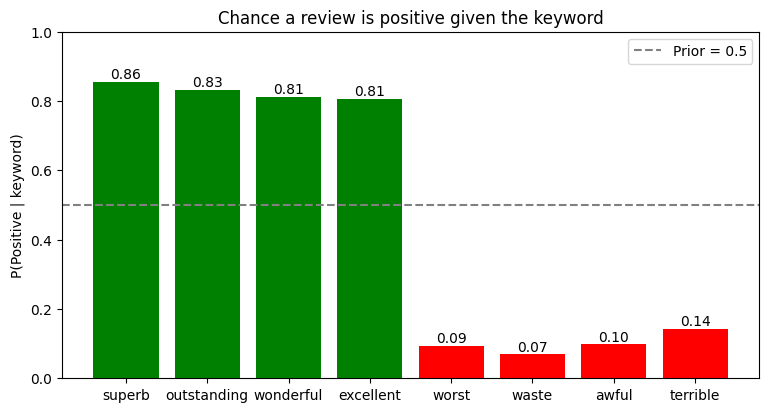

In [ ]:
import matplotlib.pyplot as plt

rows = pos + neg
names = [r["keyword"] for r in rows]
posts = [r["posterior"] for r in rows]
colors = ["green"] * len(pos) + ["red"] * len(neg)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(names, posts, color=colors)
plt.axhline(0.5, linestyle="--", color="gray", label="Prior = 0.5")
for bar, p in zip(bars, posts):
    plt.text(bar.get_x() + bar.get_width() / 2, p + 0.01, f"{p:.2f}", ha="center")
plt.ylabel("P(Positive | keyword)")
plt.title("Chance a review is positive given the keyword")
plt.ylim(0, 1)
plt.legend()
plt.savefig("posterior_chart.png", dpi=150)
plt.show()

## What the results show

- The prior is 0.5 because the dataset has 25,000 positive and 25,000 negative reviews.
- All four positive words are well above 0.5. "superb" is the highest at 0.856.
- All four negative words are well below 0.5. "waste" is the lowest at 0.069, so about 93% of the reviews that contain it are negative. A low number is what we expect for a negative word because we are calculating P(Positive | keyword).
- "excellent" has the highest likelihood (0.1146) but "superb" has the higher posterior. The posterior also depends on how often the word shows up in negative reviews, which is why we divide by P(kw).

## Limits

- It looks at one word at a time, so it misses things like "not terrible" or sarcasm.
- One word only shifts the probability, it does not decide the sentiment.
- The prior of 0.5 only holds because this dataset is balanced.

# Part 4: Gradient Descent in Code

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize, approx_fprime

##### 1. Setup Data from handwritten **maths**

In [ ]:
X = np.array([
    [1.0, 3.0],
    [4.0, 10.0]
])
y = np.array([
    [5.0],
    [6.0]
])

2.Setting initial parameters

In [ ]:
m = np.array([
    [-1.0],
    [2.0]
])
b = np.array([
    [1.0],
    [1.0]
])

alpha = 0.01
num_iterations = 3
n = len(y)

3. Calculate the starting predictions and cost

In [ ]:
y_hat_initial = X @ m + b
error_initial = y_hat_initial - y
initial_cost = (1.0 / n) * np.sum(error_initial ** 2)

print("Initial predictions y_hat =\n", y_hat_initial)
print("Initial errors =\n", error_initial)
print(f"Initial cost J = {initial_cost:.4f}")

Initial predictions y_hat =
 [[ 6.]
 [17.]]
Initial errors =
 [[ 1.]
 [11.]]
Initial cost J = 61.0000


4. history tracking

In [ ]:
m_history = [m.copy()]
b_history = [b.copy()]
cost_history = [(1.0 / n) * np.sum(error_initial**2)]

5. Step-by-step Gradient Descent Loop

In [ ]:
for i in range(1, num_iterations + 1):
    # Step 1: predictions from the current parameters
    y_hat = X @ m + b

    # Step 2: prediction errors
    error = y_hat - y

    # Step 3: gradients of the MSE cost
    dj_dm = (2.0 / n) * (X.T @ error)
    dj_db = (2.0 / n) * error  # vector bias, matching b's shape

    # Step 4: update each parameter exactly once
    m = m - alpha * dj_dm
    b = b - alpha * dj_db

    # Step 5: calculate cost using the updated parameters
    updated_y_hat = X @ m + b
    updated_error = updated_y_hat - y
    updated_cost = (1.0 / n) * np.sum(updated_error ** 2)

    # Step 6: save the updated state for plotting
    m_history.append(m.copy())
    b_history.append(b.copy())
    cost_history.append(updated_cost)
    print(f"\n{'=' * 12} ITERATION {i} {'=' * 12}")
    print("Predictions before update:\n", y_hat)
    print("Errors before update:\n", error)
    print("Gradient with respect to m:\n", dj_dm)
    print("Gradient with respect to b:\n", dj_db)
    print("Updated m:\n", m)
    print("Updated b:\n", b)
    print("Predictions after update:\n", updated_y_hat)
    print(f"Cost after update = {updated_cost:.6f}")


============ ITERATION 1 ============
Predictions before update:
 [[ 6.]
 [17.]]
Errors before update:
 [[ 1.]
 [11.]]
Gradient with respect to m:
 [[ 45.]
 [113.]]
Gradient with respect to b:
 [[ 1.]
 [11.]]
Updated m:
 [[-1.45]
 [ 0.87]]
Updated b:
 [[0.99]
 [0.89]]
Predictions after update:
 [[2.15]
 [3.79]]
Cost after update = 6.503300

============ ITERATION 2 ============
Predictions before update:
 [[2.15]
 [3.79]]
Errors before update:
 [[-2.85]
 [-2.21]]
Gradient with respect to m:
 [[-11.69]
 [-30.65]]
Gradient with respect to b:
 [[-2.85]
 [-2.21]]
Updated m:
 [[-1.3331]
 [ 1.1765]]
Updated b:
 [[1.0185]
 [0.9121]]
Predictions after update:
 [[3.2149]
 [7.3447]]
Cost after update = 2.497400

============ ITERATION 3 ============
Predictions before update:
 [[3.2149]
 [7.3447]]
Errors before update:
 [[-1.7851]
 [ 1.3447]]
Gradient with respect to m:
 [[3.5937]
 [8.0917]]
Gradient with respect to b:
 [[-1.7851]
 [ 1.3447]]
Updated m:
 [[-1.369037]
 [ 1.095583]]
Updated b:
 [

In [ ]:
print("\nFinal predictions:\n", X @ m + b)
print("Final m:\n", m)
print("Final b:\n", b)
print(f"Final cost = {cost_history[-1]:.6f}")

assert len(m_history) == num_iterations + 1
assert len(b_history) == num_iterations + 1
assert len(cost_history) == num_iterations + 1
print("\nCheck passed: exactly three updates were recorded.")


Final predictions:
 [[2.954063]
 [6.378335]]
Final m:
 [[-1.369037]
 [ 1.095583]]
Final b:
 [[1.036351]
 [0.898653]]
Final cost = 2.164498

Check passed: exactly three updates were recorded.


6. Scipy Minimization Verification

In [ ]:
def cost_from_flat_params(params):
    """Return the MSE cost for flattened [m1, m2, b1, b2] parameters."""
    m_values = params[:2].reshape(2, 1)
    b_values = params[2:4].reshape(2, 1)
    predictions = X @ m_values + b_values
    return (1.0 / n) * np.sum((predictions - y) ** 2)


def compute_scipy_gradient(function, params, epsilon=1e-6):
    """Estimate a scalar function's gradient with SciPy finite differences."""
    return approx_fprime(params, function, epsilon)

final_params = np.concatenate([m.ravel(), b.ravel()])
scipy_gradient = compute_scipy_gradient(cost_from_flat_params, final_params)

 #### Analytical gradient evaluated at exactly the same final parameters.

In [ ]:
final_error = (X @ m + b) - y
analytic_dm = (2.0 / n) * (X.T @ final_error)
analytic_db = (2.0 / n) * final_error
analytic_gradient = np.concatenate([analytic_dm.ravel(), analytic_db.ravel()])

parameter_names = ["m1", "m2", "b1", "b2"]
print("Gradient comparison at final parameters:")
for name, analytic, numerical in zip(parameter_names, analytic_gradient, scipy_gradient):
    print(f"{name}: analytical = {analytic: .8f} | SciPy numerical = {numerical: .8f}")

max_difference = np.max(np.abs(analytic_gradient - scipy_gradient))
print(f"\nMaximum absolute difference = {max_difference:.2e}")
assert np.allclose(analytic_gradient, scipy_gradient, atol=1e-4, rtol=1e-4)
print("Check passed: SciPy's numerical gradients agree with the analytical gradients.")

Gradient comparison at final parameters:
m1: analytical = -0.53259700 | SciPy numerical = -0.53258850
m2: analytical = -2.35446100 | SciPy numerical = -2.35440650
b1: analytical = -2.04593700 | SciPy numerical = -2.04593650
b2: analytical =  0.37833500 | SciPy numerical =  0.37833550

Maximum absolute difference = 5.45e-05
Check passed: SciPy's numerical gradients agree with the analytical gradients.


##### 4. Matplotlib Visualization

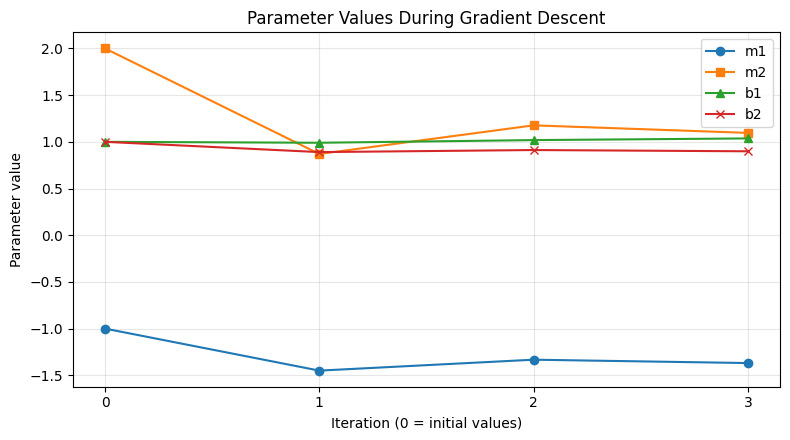

In [ ]:
m_hist = np.vstack([item.reshape(1, 2) for item in m_history])
b_hist = np.vstack([item.reshape(1, 2) for item in b_history])
steps = np.arange(num_iterations + 1)

# Plot 1: how the parameters change from iteration 0 through iteration 3
plt.figure(figsize=(8, 4.5))
plt.plot(steps, m_hist[:, 0], marker="o", label="m1")
plt.plot(steps, m_hist[:, 1], marker="s", label="m2")
plt.plot(steps, b_hist[:, 0], marker="^", label="b1")
plt.plot(steps, b_hist[:, 1], marker="x", label="b2")
plt.title("Parameter Values During Gradient Descent")
plt.xlabel("Iteration (0 = initial values)")
plt.ylabel("Parameter value")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

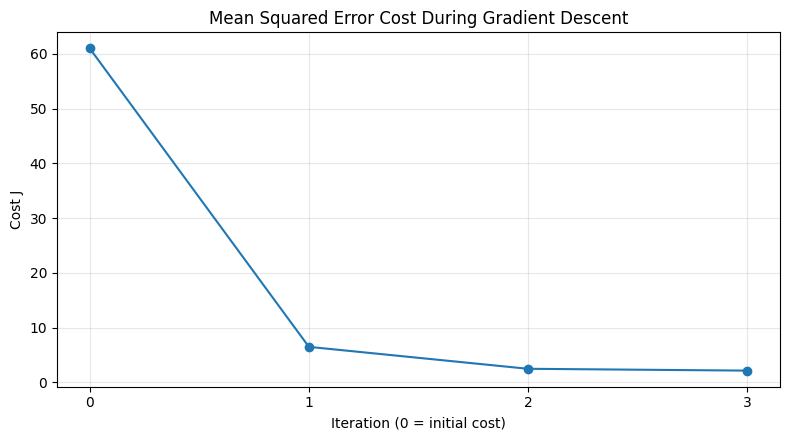

Cost history: [np.float64(61.0), np.float64(6.5033), np.float64(2.4974), np.float64(2.164498)]


In [ ]:
# Plot 2: cost at the initial state and after each update
plt.figure(figsize=(8, 4.5))
plt.plot(steps, cost_history, marker="o")
plt.title("Mean Squared Error Cost During Gradient Descent")
plt.xlabel("Iteration (0 = initial cost)")
plt.ylabel("Cost J")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Cost history:", [round(value, 6) for value in cost_history])